# Поиск инсайтов и точек роста

Для работы предоставлены данные сервиса доставки еды «Всё.из.кафе». Руководство ждёт от продукта роста. Необходимо найти инсайты, которые позволят сервису повысить показатель удержания пользователей и улучшить взаимодействие с партнёрами.

Необходимо помочь бизнесу ответить на следующие вопросы:
- Как ведут себя пользователи? Как наиболее эффективно выстроить работу с ними, чтобы они продолжали пользоваться продуктом?
- Какой путь проходят пользователи в сервисе? Где «проваливаются»?
- Как улучшить взаимодействие с партнёрами-ресторанами?

### Задачи 

Провести комплексный анализ данных:
- Изучить пользовательский путь и проанализировать конверсии через воронки;
- Сегментировать пользователей с помощью RFM-модели для оценки лояльности и поведения клиентов;
- Кластеризировать рестораны методом K-Means, чтобы выделить группы с разными моделями работы и разработать персонализированные маркетинговые стратегии.

Такой подход позволит ближе познакомиться с работой сервиса, выявить узкие места и предложить решения для удержания пользователей и повышения эффективности сотрудничества с ресторанами.


### Данные

Данные включают следующие сведения:
- `visitor_uuid` — идентификатор посетителя. Это идентификатор, который присваивается системой любому новому пользователю вне зависимости от того, зарегистрировался он в продукте или нет.
- `user_id` — идентификатор зарегистрированного пользователя. Присваивается посетителю после создания учётной записи: ввода логина, пароля, адреса доставки и контактных данных.
- `device_type` — тип платформы, с которой посетитель зашёл в продукт.
- `city_id` — город, из которого посетитель зашёл в сервис.
- `source` — рекламный источник привлечения посетителя.
- `first_date` — дата первого посещения продукта.
- `visit_id` — уникальный идентификатор сессии.
- `event` — название аналитического события.
- `datetime` — дата и время события.
- `rest_id` — уникальный идентификатор ресторана (заполняется для заказов, карточек ресторанов и блюд).
- `object_id` — уникальный идентификатор блюда (заполняется для заказов и карточек блюд).
- `order_id` — уникальный идентификатор заказа.
- `revenue` — выручка от заказа (в рублях). Это та сумма, которую пользователь видит при оплате.
- `delivery` — стоимость доставки (в рублях).
- `commission` — комиссия, которую «Всё.из.кафе» берёт с выручки ресторана, в процентах.

    
### План проекта

- Загрузка данных и их предобработка.
- Анализ пользовательского пути новых пользователей.
- RFM сегментация.
- K-Means кластеризация.
- Итоговый вывод и рекомендации.

## Загрузка данных и их предобработка

Загрузим данные. Проведём необходимую предобработку.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D

In [2]:
df = pd.read_csv('https://code.s3.yandex.net/datasets/insides_data.csv', parse_dates = ['first_date','datetime'])

In [3]:
df.head()

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   visitor_uuid  205510 non-null  object        
 1   user_id       205510 non-null  float64       
 2   device_type   205510 non-null  object        
 3   city_id       205510 non-null  int64         
 4   source        205510 non-null  object        
 5   first_date    205510 non-null  datetime64[ns]
 6   visit_id      205510 non-null  int64         
 7   event         205510 non-null  object        
 8   datetime      205510 non-null  datetime64[ns]
 9   rest_id       166915 non-null  object        
 10  object_id     21308 non-null   float64       
 11  order_id      7008 non-null    float64       
 12  revenue       7008 non-null    float64       
 13  delivery      7008 non-null    float64       
 14  commission    21308 non-null   float64       
dtypes: datetime64[ns]

Всего в датафрейме 205510 строк. Пропуски есть в столбцах `rest_id`, `object_id`, `order_id`, `revenue`, `delivery`, `commission`. Это не проблема, так как не все варианты событий из столбца `event` дают информацию для этих столбцов.

In [5]:
start_count = len(df)
start_count

205510

Записи охватывают временной период с `2021-04-30` по `2021-07-02`. Данные есть за примерно 2 месяца.

In [6]:
df['datetime'].min()

Timestamp('2021-05-01 00:10:55')

In [7]:
df['datetime'].max()

Timestamp('2021-07-02 00:12:08')

In [8]:
df['first_date'].min()

Timestamp('2021-04-30 00:00:00')

In [9]:
df['first_date'].max()

Timestamp('2021-07-01 00:00:00')

Рассмотрим столбец `visitor_uuid` с идентификаторами посетителей.

In [10]:
unique_visitors = df['visitor_uuid'].nunique()
unique_visitors

8891

In [11]:
duplicate_visitor = df['visitor_uuid'].value_counts()
duplicate_visitor = duplicate_visitor[duplicate_visitor > 1]
duplicate_visitor

1b235f7d-c696-474c-95d8-c7bee990a855    939
35877b4e-768d-48d5-b6cc-6ef9fde7e5e4    800
841bf5b2-e12e-480e-8a9a-a1500a094d99    609
3473a33f-381c-42cc-902b-65f3178f30d8    598
0ec1a5e3-4db4-4fb4-827a-bef99c08dd4d    476
                                       ... 
1320311f-125b-4fa8-a2cb-e36efbd9bb01      2
03c38e15-9de1-4719-be54-d2e7b67c86d0      2
4d6ad803-5d58-4ca6-9401-b95016f23163      2
ef48a856-eec4-4bda-b877-e9862cfabe11      2
78b70400-0c40-4dea-bca9-b7467cf5f6fd      2
Name: visitor_uuid, Length: 8409, dtype: int64

In [12]:
uuid = '1b235f7d-c696-474c-95d8-c7bee990a855'
uuid_act = df[df['visitor_uuid'] == uuid]
uuid_act

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
101418,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,181197230,login,2021-06-02 21:32:35,NaN,NaN,NaN,NaN,NaN,NaN
101419,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,181197230,authorization,2021-06-02 21:32:46,NaN,NaN,NaN,NaN,NaN,NaN
101420,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,181199558,login,2021-06-02 21:38:02,NaN,NaN,NaN,NaN,NaN,NaN
101421,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,181199558,authorization,2021-06-02 21:38:13,NaN,NaN,NaN,NaN,NaN,NaN
101422,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,181200053,login,2021-06-02 21:39:01,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168880,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,188428170,add_to_cart,2021-06-18 13:41:49,4a693ca500b44ba499f92a724aec5f17,29859.0,NaN,NaN,NaN,0.06
168881,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,188428170,object_page,2021-06-18 13:41:52,4a693ca500b44ba499f92a724aec5f17,29859.0,NaN,NaN,NaN,0.06
168882,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,188428170,login,2021-06-18 13:54:55,NaN,NaN,NaN,NaN,NaN,NaN
168883,1b235f7d-c696-474c-95d8-c7bee990a855,248189.0,Desktop,6,organic,2021-05-30,188428170,add_to_cart,2021-06-18 13:55:03,55d4027ac83e438f9f893892f6903409,25069.0,657030.0,13440.0,25.7,0.05


In [13]:
uuid_visits = uuid_act['visit_id'].nunique()
uuid_visits

24

У самого активного пользователя 24 визита в сервис доставки, учитывая временной промежуток датафрейма, он заходил почти через день. Изучим другие столбцы.

In [14]:
unique_users = df['user_id'].nunique()
unique_users

8473

Большая часть посетителей зарегестрировалась.

In [15]:
df['device_type'].value_counts()

Desktop    159119
Mobile      46391
Name: device_type, dtype: int64

In [16]:
df['city_id'].value_counts()

6    188305
5     10617
4      2844
2      2517
1       844
3       383
Name: city_id, dtype: int64

In [17]:
df['source'].value_counts()

organic     101565
Source_B     61435
Source_C     32558
Source_A      9952
Name: source, dtype: int64

Есть явный лидер `6` среди городов, на него приходится больше всего заказов. Пользователи предпочитают десктопную версию сервиса. Половина трафика - органическая. Самый слабый источник привлечения - `Source_A`.

In [18]:
df['event'].value_counts()

main_page        145607
login             18581
object_page       12132
authorization      9983
reg_page           5684
add_to_cart        5627
confirm_phone      4347
order              3549
Name: event, dtype: int64

Всего 8 типов события. Заказов совершено 3549, для каждого есть информация по выручке.

In [19]:
orders = df[df['event'] == 'order']
orders_no_revenue = orders['revenue'].isna().sum()
orders_no_revenue_p = (orders_no_revenue / 3549) * 100
orders_no_revenue_p

0.0

Посмотрим событие подтверждения телефонов, чтобы проверить, как работают события.

In [20]:
conf = df[df['event'] == 'confirm_phone']
conf_counts = conf.groupby('user_id').size().reset_index(name = 'conf_count')
conf_counts['conf_count'].value_counts().sort_index()
err_confirm = conf_counts[conf_counts['conf_count'] > 1]
err_confirm

,user_id,conf_count
1,5506.0,2
21,32995.0,2
68,69273.0,2
89,82742.0,2
91,83286.0,2
...,...,...
4070,641441.0,2
4079,641660.0,2
4094,641996.0,2
4132,643218.0,2


In [21]:
conf_counts['conf_count'].value_counts()

1    4042
2     140
3       7
4       1
Name: conf_count, dtype: int64

Получается, 140 пользователей дважды подтверждали телефон, 7 - трижды, и один 4 раза.

In [22]:
err_confirm_2 = conf_counts[conf_counts['conf_count'] > 2]
err_confirm_2

,user_id,conf_count
135,120736.0,3
297,239407.0,3
601,412883.0,3
807,527040.0,3
893,546237.0,3
1264,571672.0,3
2101,592378.0,4
2143,593354.0,3


In [23]:
id_conf = df[df['user_id'] == 120736.0]
id_conf = id_conf[id_conf['event'] == 'confirm_phone']
id_conf

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
31273,5a3133e6-a7ed-40db-ba3f-9b9e53e58d1f,120736.0,Desktop,6,Source_B,2021-05-11,174230341,confirm_phone,2021-05-11 13:02:13,NaN,NaN,NaN,NaN,NaN,NaN
50426,45839eaa-58be-4b55-8cc4-317eb4266a87,120736.0,Desktop,6,Source_B,2021-05-19,176703373,confirm_phone,2021-05-19 13:17:02,NaN,NaN,NaN,NaN,NaN,NaN
160891,dda6f9e9-98ad-443e-a20d-35e6fec2b3b4,120736.0,Desktop,6,organic,2021-06-15,187243230,confirm_phone,2021-06-15 16:52:39,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
id_conf_2 = df[df['user_id'] == 592378.0]
id_conf_2 = id_conf_2[id_conf_2['event'] == 'confirm_phone']
id_conf_2

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
63419,9925805b-b458-45cb-9948-bee64556f24a,592378.0,Desktop,6,organic,2021-05-23,178007374,confirm_phone,2021-05-23 15:02:56,NaN,NaN,NaN,NaN,NaN,NaN
83765,d6fe9dcb-b816-4094-8393-e74a18298f8a,592378.0,Desktop,6,Source_B,2021-05-28,179568267,confirm_phone,2021-05-28 20:52:56,NaN,NaN,NaN,NaN,NaN,NaN
87151,91f9552e-6604-464d-ab0d-857a5c5db766,592378.0,Desktop,6,Source_B,2021-05-29,179738128,confirm_phone,2021-05-29 13:28:10,NaN,NaN,NaN,NaN,NaN,NaN
156162,7cd564b9-30df-409c-83e8-3e418940b7b5,592378.0,Desktop,6,Source_B,2021-06-14,186576262,confirm_phone,2021-06-14 09:43:18,NaN,NaN,NaN,NaN,NaN,NaN


Подтверждение телефона это финальная стадия регистрации, при этом на одинаковый `user_id` приходится несколько подтверждений. Может для надёжности нужно несколько раз подтверждать номер, например после долгого отсутствия или подозрительных действий. Но судя по датам это не тот случай, поэтому удалим таких пользователей, чтоб нормально построить нормальную воронку.

In [25]:
remove_users = err_confirm['user_id'].unique()
df = df[~df['user_id'].isin(remove_users)].copy()

In [26]:
unique_users_2 = df['user_id'].nunique()
unique_users_2

8325

In [27]:
df['rest_id'].value_counts()

8d9fb9d5992f400eaf02660973a66adf    12970
55d4027ac83e438f9f893892f6903409    12184
1be5a933aab34fbab594bebba48e976e     7711
1d6bb74687104fa1953924c9684fe624     7645
a29747e18d3f4ff487b355d34312aacb     7614
8c9307a1485d4f8aa48c6746e46540d8     7502
4a693ca500b44ba499f92a724aec5f17     7351
5b262d151ec1410e94602e422c525c3d     7311
815a6b063cd84005b02b1fc3b48af951     7306
59fc1a894303462e8205a759d906499c     7007
8d4f8073da2945c6bd8615fa95c74852     6967
56edd124dfa44656afe0c0d041eba562     6821
43e40bacafe8409bb5592877a42d737e     6686
fe285c3040794705afbc17089aafc687     6567
55d6470712ee48e98509478ad6aa18ee     6521
a59b5279a8674d7a8a16fbf5d92b5551     6496
39b7eab4f4704ed2886fafe171489960     6484
3247a3b5f9494812a3c1a73c5b61f004     6445
c91517a6ca264aadae9725e1774d93ca     6423
4b9cde3378c447ed81c2c6d4854d4f7e     6352
2c6095730b514c189ee41c65f03febc3     6181
Name: rest_id, dtype: int64

In [28]:
len(df['rest_id'].value_counts())

21

В датафрейме события относятся к 21 ресторану.

In [29]:
df['revenue'].describe()

count     6668.000000
mean      2497.667451
std       2058.950280
min        235.200000
25%       1302.000000
50%       1944.600000
75%       3136.000000
max      42000.000000
Name: revenue, dtype: float64

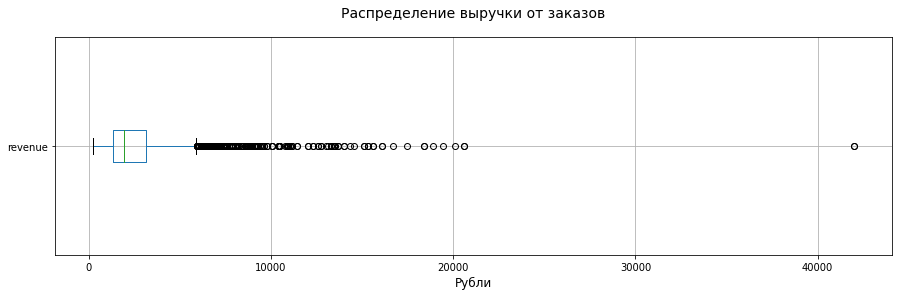

In [30]:
err_revenue = df.boxplot(
    column = 'revenue',
    vert = False,
    showfliers = True
)

fig = plt.gcf()
fig.set_size_inches(15, 4)

err_revenue.set_title('Распределение выручки от заказов', fontsize = 14, pad = 20)
err_revenue.set_xlabel('Рубли', fontsize = 12)

plt.show()

В данных по выручке есть один явный выброс на 42000 рублей и много выбросов в правый хвост. Правый ус заканчивается примерно на 6000 рублях. Посмотрим, сколько особо крупных заказов. Уберём выбросы методом квартилей с коэффициентом 3, чтобы не отбрасывать крупные заказы.

In [31]:
len(df[df['revenue'] > 6000])

319

In [32]:
def iqr_mask(group):
    q1 = group.quantile(0.25)
    q3 = group.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 3 * iqr
    upper_bound = q3 + 3 * iqr
    in_range_mask = (group >= lower_bound) & (group <= upper_bound)
    nan_mask = group.isna()
    return in_range_mask | nan_mask

df_mask = iqr_mask(df['revenue'])
df = df[df_mask]
df = df.reset_index(drop=True)

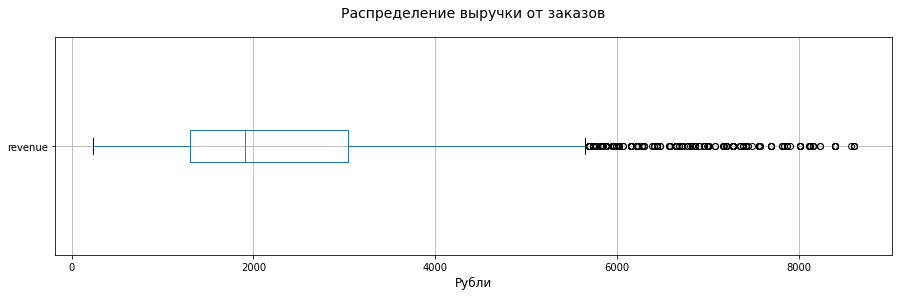

In [33]:
norm_revenue = df.boxplot(
    column = 'revenue',
    vert = False,
    showfliers = True
)

fig = plt.gcf()
fig.set_size_inches(15, 4)

norm_revenue.set_title('Распределение выручки от заказов', fontsize = 14, pad = 20)
norm_revenue.set_xlabel('Рубли', fontsize = 12)

plt.show()

In [34]:
df['revenue'].describe()

count    6558.000000
mean     2331.651848
std      1490.014024
min       235.200000
25%      1297.128000
50%      1904.000000
75%      3041.500000
max      8610.000000
Name: revenue, dtype: float64

Теперь распределение адекватное.

In [35]:
df['delivery'].describe()

count    6558.000000
mean       24.525541
std         8.657629
min         9.900000
25%        17.000000
50%        24.200000
75%        32.100000
max        39.900000
Name: delivery, dtype: float64

In [36]:
df['commission'].describe()

count    19837.000000
mean         0.055935
std          0.012112
min          0.040000
25%          0.050000
50%          0.050000
75%          0.060000
max          0.110000
Name: commission, dtype: float64

Проверим аномалии в данных, проверим ещё раз дубликаты, типы данных.

In [37]:
mask = df['datetime'] < df['first_date']
df[mask]

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission


In [38]:
df_err_revenue = (df['revenue'] <= 0).sum()
df_err_revenue

0

In [39]:
df_err_delivery = (df['delivery'] <= 0).sum()
df_err_delivery

0

In [40]:
df_err_commission = (df['commission'] <= 0).sum()
df_err_commission

0

In [41]:
df['user_id'] = df['user_id'].astype('Int64')
df['device_type'] = df['device_type'].str.lower()
df['source'] = df['source'].str.lower()

In [42]:
df.duplicated().sum()

0

In [43]:
df.head()

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317,desktop,6,source_b,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317,desktop,6,source_b,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317,desktop,6,source_b,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317,desktop,6,source_b,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317,desktop,6,source_b,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN


In [44]:
df.tail()

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
192785,fa03bc4e-a8d6-45b2-9df0-29e6e8449fd8,641931,desktop,6,organic,2021-06-28,193825829,authorization,2021-07-01 14:02:36,NaN,NaN,NaN,NaN,NaN,NaN
192786,fa03bc4e-a8d6-45b2-9df0-29e6e8449fd8,641931,desktop,6,organic,2021-06-28,193825829,main_page,2021-07-01 14:22:00,56edd124dfa44656afe0c0d041eba562,NaN,NaN,NaN,NaN,NaN
192787,fbf7a714-cb1d-492a-ae30-b45d02b44989,616472,desktop,6,organic,2021-07-01,193987971,login,2021-07-02 00:11:57,NaN,NaN,NaN,NaN,NaN,NaN
192788,fbf7a714-cb1d-492a-ae30-b45d02b44989,616472,desktop,6,organic,2021-07-01,193987971,add_to_cart,2021-07-02 00:12:05,8c9307a1485d4f8aa48c6746e46540d8,27807.0,675680.0,1400.0,28.0,0.05
192789,fbf7a714-cb1d-492a-ae30-b45d02b44989,616472,desktop,6,organic,2021-07-01,193987971,order,2021-07-02 00:12:08,8c9307a1485d4f8aa48c6746e46540d8,27807.0,675680.0,1400.0,28.0,0.05


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192790 entries, 0 to 192789
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   visitor_uuid  192790 non-null  object        
 1   user_id       192790 non-null  Int64         
 2   device_type   192790 non-null  object        
 3   city_id       192790 non-null  int64         
 4   source        192790 non-null  object        
 5   first_date    192790 non-null  datetime64[ns]
 6   visit_id      192790 non-null  int64         
 7   event         192790 non-null  object        
 8   datetime      192790 non-null  datetime64[ns]
 9   rest_id       156434 non-null  object        
 10  object_id     19837 non-null   float64       
 11  order_id      6558 non-null    float64       
 12  revenue       6558 non-null    float64       
 13  delivery      6558 non-null    float64       
 14  commission    19837 non-null   float64       
dtypes: Int64(1), date

In [46]:
end_count = len(df)
end_count

192790

In [47]:
df_afret = (end_count / start_count) * 100
df_afret

93.81052016933482

После предобработки осталось 93,8% исходных данных. Предоставленная информация качественная, нет дубликатов, пропуски только в уместных местах, значения почти адекватные. Есть проблемы с событием подтверждения номера телефона, проблемные записи убрали. Можно переходить к следующему шагу исследования.

---

## Анализ пользовательского пути

Маркетологи стали замечать следующее: деньги на рекламу по-прежнему тратятся, а заказов стало меньше. И это несмотря на то, что приложение скачивается и устанавливается так же активно, как раньше. Складывается ощущение, что пользователи где-то теряются. При этом доля заказов с десктопной версии приложения увеличилась по сравнению с мобильной.

Разработчики говорят, что последние обновления мобильной версии приложения не должны были повлиять на каталог блюд или его выбор для заказа и последующей оплаты доставки, так как изменения касались нового алгоритма подтверждения мобильного телефона и адреса доставки.

С помощью воронок изучим общий пользовательский путь новых пользователей, затем сравним поведение пользователей мобильной и десктопной версий приложения. 

**Задача 2.1.** Построим и визуализируем общую воронку (по всем данным), затем опишем пользовательский путь: какие этапы представлены, какова их последовательность, на каком (или на каких) этапах теряется большая часть новых пользователей.
    
При решении построим две воронки: 
- классическую воронку — доля от первого шага в процентах
- step-by-step — с конверсией от предыдущего этапа.

Предполагается, что пользователь проходит такой путь к оформлению доставки блюда из ресторанов:
1. `authorization` — авторизация пользователя — запуск приложения.
2. `main_page` — загрузка основной страницы приложения.
2. `reg_page` — переход на страницу регистрации.
2. `confirm_phone` — подтверждение телефона (окончание процесса регистрации).
2. `object_page` — страница блюда.
2. `add_to_cart` — переход в корзину.
2. `order` — оформление заказа.    

Поскольку заказать можно только подтвердив телефон, будем считать воронку по уникальным `user_id`.

In [48]:
steps = ['authorization', 'main_page', 'reg_page', 'confirm_phone', 'object_page', 'add_to_cart', 'order']

df_steps = df[df['event'].isin(steps)]
df_steps_counts = df_steps.groupby('event')['user_id'].nunique().reindex(steps)

funnel_df = pd.DataFrame({
   'step': df_steps_counts.index,
   'users': df_steps_counts.values
})

first_step_users = funnel_df.loc[0, 'users']
funnel_df['conversion_from_first_%'] = (funnel_df['users'] / first_step_users * 100).round(1)
funnel_df['conversion_from_previous_%'] = (funnel_df['users'] / funnel_df['users'].shift(1) * 100).round(1)

funnel_df

,step,users,conversion_from_first_%,conversion_from_previous_%
0,authorization,7271,100.0,NaN
1,main_page,6395,88.0,88.0
2,reg_page,5269,72.5,82.4
3,confirm_phone,4042,55.6,76.7
4,object_page,3318,45.6,82.1
5,add_to_cart,2762,38.0,83.2
6,order,2292,31.5,83.0


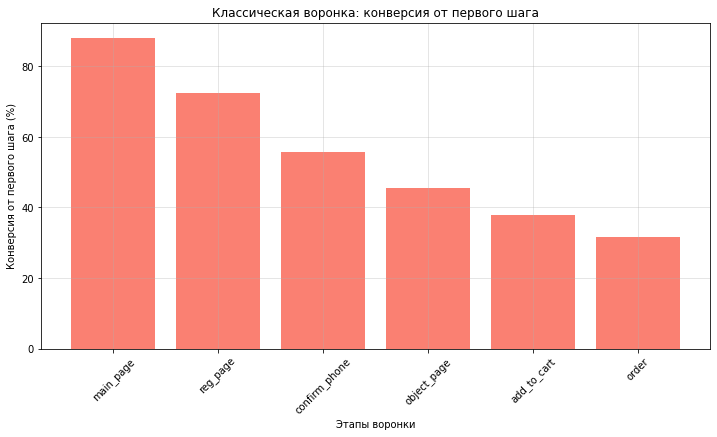

In [49]:
plt.figure(figsize = (12, 6))

plot_df = funnel_df.iloc[1:]

plt.bar(
    plot_df['step'], 
    plot_df['conversion_from_first_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Классическая воронка: конверсия от первого шага')
plt.ylabel('Конверсия от первого шага (%)')
plt.xlabel('Этапы воронки')

plt.show()

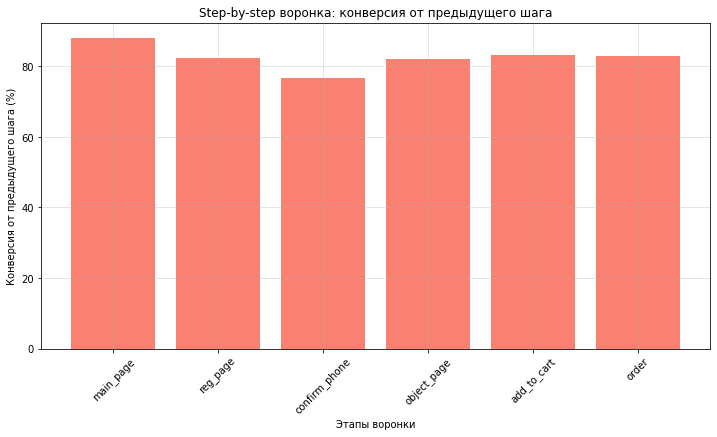

In [50]:
plt.figure(figsize = (12, 6))

plot_df = funnel_df.iloc[1:]

plt.bar(
    plot_df['step'], 
    plot_df['conversion_from_previous_%'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Step-by-step воронка: конверсия от предыдущего шага')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')

plt.show()

Видна относительно сильная просадка на этапе подтверждения телефона в воронке `Step-by-step`. В классической этот этам тоже самый явный. Похоже  новый алгоритм подтверждения мобильного телефона и адреса доставки всё же имел эффект, посмотрим на воронку в разрезе платформы.

**Задача 2.2.** Сравним пользовательский путь в двух приложениях: в мобильной версии и десктопной. Для этого построем и визуализируем две воронки step-by-step: для новых пользователей мобильной и десктопной версий приложения. Сравним результаты между собой и проанализируем, есть ли различия в пользовательском пути для различных приложений.

In [51]:
mobile_df = df[df['device_type'] == 'mobile']
desktop_df = df[df['device_type'] == 'desktop']

counts_desktop = desktop_df[desktop_df['event'].isin(steps)]
counts_desktop_agg = counts_desktop.groupby('event')['user_id'].nunique().reindex(steps)
desktop_funnel = (counts_desktop_agg / counts_desktop_agg.shift(1) * 100).round(1)

counts_mobile = mobile_df[mobile_df['event'].isin(steps)]
counts_mobile_agg = counts_mobile.groupby('event')['user_id'].nunique().reindex(steps)
mobile_funnel = (counts_mobile_agg / counts_mobile_agg.shift(1) * 100).round(1)

funnel_compare_df = pd.DataFrame({
    'step': steps[1:],
    'mobile': mobile_funnel.iloc[1:].values,
    'desktop': desktop_funnel.iloc[1:].values
})

funnel_compare_df

,step,mobile,desktop
0,main_page,83.1,90.8
1,reg_page,87.8,78.5
2,confirm_phone,53.9,89.8
3,object_page,73.6,85.7
4,add_to_cart,85.8,82.3
5,order,85.8,81.9


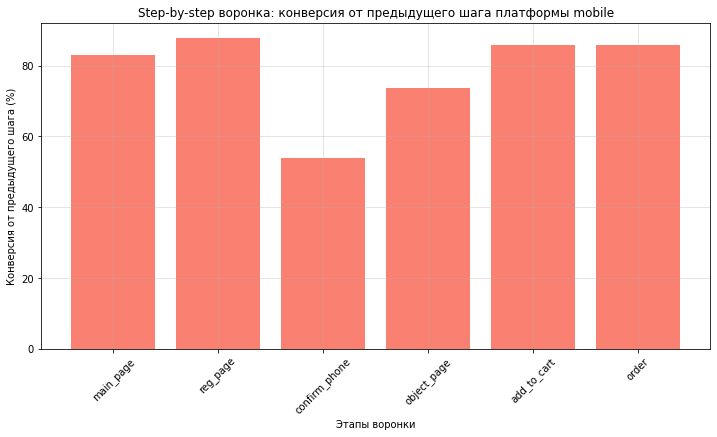

In [52]:
plt.figure(figsize = (12, 6))

plt.bar(
    funnel_compare_df['step'], 
    funnel_compare_df['mobile'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Step-by-step воронка: конверсия от предыдущего шага платформы mobile')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')

plt.show()

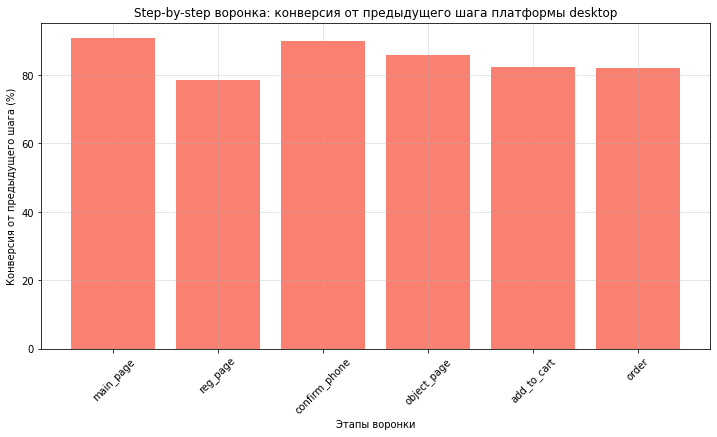

In [53]:
plt.figure(figsize = (12, 6))

plt.bar(
    funnel_compare_df['step'], 
    funnel_compare_df['desktop'], 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.title('Step-by-step воронка: конверсия от предыдущего шага платформы desktop')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')

plt.show()

У мобильной версии приложения явные проблемы с этапом регистрации. Конверсия с главной страницы на регистрацию высокая, а потом проседает и в десктопной версии на 10%, и в мобильной больше, чем на 20%. Дальше шаги выравниваются. Возможно проблема в интерфейса или внутренней системе, долгой загрузки.

In [54]:
df_time = df.copy()
df_time['session'] = df_time['user_id'].astype(str) + '_' + df_time['datetime'].dt.date.astype(str)

deltas_mobile = {}
deltas_desktop = {}

def get_median_delta(df_subset, step1, step2):
    t1 = df_subset[df_subset['event'] == step1][['user_id', 'session', 'datetime']].copy()
    t2 = df_subset[df_subset['event'] == step2][['user_id', 'session', 'datetime']].copy()
    
    if t1.empty or t2.empty:
        return None

    t1_grp = t1.sort_values('datetime').groupby(['user_id', 'session']).first().reset_index()
    t2_grp = t2.sort_values('datetime').groupby(['user_id', 'session']).first().reset_index()

    merged = pd.merge(t1_grp, t2_grp, on = ['user_id', 'session'], suffixes = ('_start', '_end'))
    
    if merged.empty:
        return None

    merged['delta'] = (merged['datetime_end'] - merged['datetime_start']).dt.total_seconds()
    merged = merged[merged['delta'] >= 0]
    
    if merged.empty:
        return None
        
    return round(merged['delta'].median(), 1)

for i in range(1, len(steps)):
    step1, step2 = steps[i-1], steps[i]

    df_mobile = df_time[df_time['device_type'] == 'mobile']
    deltas_mobile[f'{step1} to {step2}'] = get_median_delta(df_mobile, step1, step2)

    df_desktop = df_time[df_time['device_type'] == 'desktop']
    deltas_desktop[f'{step1} to {step2}'] = get_median_delta(df_desktop, step1, step2)

comparison_df = pd.DataFrame({
    'step': list(deltas_mobile.keys()),
    'mobile_users_median_sec': list(deltas_mobile.values()),
    'desktop_users_median_sec': list(deltas_desktop.values())
})

comparison_df

,step,mobile_users_median_sec,desktop_users_median_sec
0,authorization to main_page,271.0,165.0
1,main_page to reg_page,87.0,158.0
2,reg_page to confirm_phone,3.0,3.0
3,confirm_phone to object_page,287.0,191.0
4,object_page to add_to_cart,584.5,466.0
5,add_to_cart to order,3.0,3.0


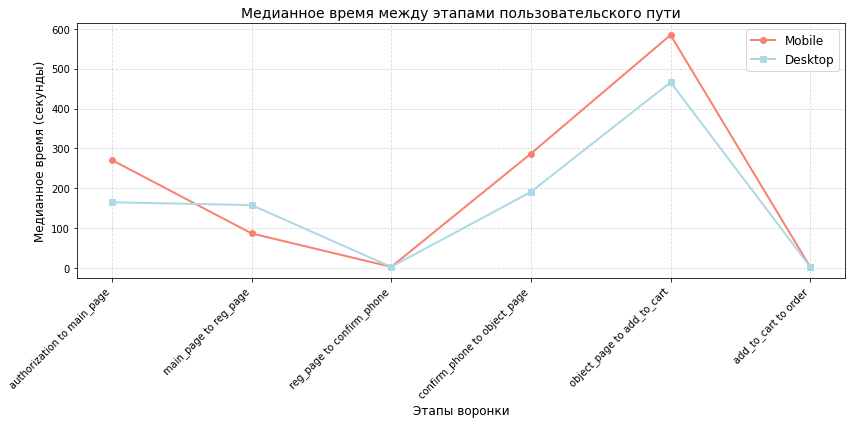

In [55]:
plt.figure(figsize=(12, 6))

plt.plot(
    comparison_df['step'],
    comparison_df['mobile_users_median_sec'],
    marker = 'o',
    linestyle = '-',
    color = 'salmon',
    linewidth = 2,
    label = 'Mobile'
)

plt.plot(
    comparison_df['step'],
    comparison_df['desktop_users_median_sec'],
    marker = 's',
    linestyle = '-',
    color = 'lightblue',
    linewidth = 2,
    label = 'Desktop'
)

plt.title('Медианное время между этапами пользовательского пути', fontsize = 14)
plt.xlabel('Этапы воронки', fontsize = 12)
plt.ylabel('Медианное время (секунды)', fontsize = 12)

plt.legend(fontsize = 12)
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()

plt.show()

На этапе `confirm_phone → object_page` у мобильных пользователей уходит намного больше времени, чем у десктопных. следующий шаг `object_page → add_to_cart` схож по расхождению. Это может говорить о трудностях подтверждения номера телефона: вероятно, интерфейс неудобен, не загружается или сервер долго отвечает. Разработчики передали, что последние обновления мобильной версии приложения не должны были повлиять, так как изменения касались нового алгоритма подтверждения мобильного телефона и адреса доставки. Данные показывают, что влияние было, и это ухудшило опыт пользователей. Упрощение UI/UX или анализ технической части — логичный первый шаг для роста конверсии. Нужно проверить мобильную версию на этапе подтверждения номера (и можно посмотреть, есть ли проблемы регистрации у десктопа).

---

## RFM сегментация

У сервиса доставки еды не такое высокое удержание пользователей: в первый день возвращается около 14% посетителей, а на седьмой день и того меньше — около 4–5%. Маркетологи хотят запустить несколько рекламных кампаний, направленных на удержание платящих пользователей и их возврат в сервис, если они давно не совершали заказы.

Для этого необходимо сегментировать пользователей на различные поведенческие сегменты с помощью RFM-сегментации по трём показателям: 
- Давность (Recency), 
- Частота покупок (Frequency), 
- Сумма трат (Monetary).

**Задача 3.1.** Для каждого покупателя посчитаем:
- Количество дней с последней покупки — давность (R);
- Частоту покупок (F);
- Стоимость всех покупок — сумму трат (M).
    
В качестве даты анализа установим 03 июля 2021 года. После этого построим три гистограммы и проанализируем их.

In [56]:
orders_df = df[df['order_id'].notna()].copy()
orders_df = orders_df[orders_df['event'] == 'order'].reset_index(drop=True)
orders_df

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,0917eb10-d393-4d7e-a911-8721571cb499,567210,mobile,6,organic,2021-05-01,171460594,order,2021-05-01 14:52:17,56edd124dfa44656afe0c0d041eba562,25349.0,590313.0,1143.156,28.1,0.04
1,0c858e35-00cb-4d8b-ad9f-d19b3b627c2f,210853,desktop,6,organic,2021-05-01,171515445,order,2021-05-01 18:45:48,39b7eab4f4704ed2886fafe171489960,35102.0,590707.0,1663.200,18.2,0.11
2,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:34:35,55d4027ac83e438f9f893892f6903409,25069.0,591008.0,3500.000,10.8,0.05
3,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:43:34,1d6bb74687104fa1953924c9684fe624,31738.0,591028.0,610.400,38.7,0.08
4,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:44:52,1d6bb74687104fa1953924c9684fe624,31738.0,591034.0,1220.800,15.6,0.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3314,bf63c410-8897-4b85-87a4-43db9321e5a7,645976,desktop,6,organic,2021-07-01,194013851,order,2021-07-01 23:58:02,55d4027ac83e438f9f893892f6903409,22966.0,675670.0,1106.000,39.4,0.05
3315,c6b9b488-0a00-4e34-a9b0-f8c9502549f6,645177,desktop,6,source_b,2021-06-29,193775224,order,2021-07-01 11:54:18,8d9fb9d5992f400eaf02660973a66adf,35798.0,674748.0,2450.000,22.0,0.05
3316,dd364d77-5bf0-4a0a-ba21-2bb768ab655e,645957,desktop,6,organic,2021-06-23,194012330,order,2021-07-01 23:43:47,56edd124dfa44656afe0c0d041eba562,25349.0,675652.0,3591.784,14.0,0.04
3317,e237d374-f0b5-4488-b50f-f5e1ae099b23,633037,mobile,6,organic,2021-06-21,193784906,order,2021-07-01 12:06:23,815a6b063cd84005b02b1fc3b48af951,27829.0,674761.0,2268.000,17.5,0.04


In [57]:
orders_df['revenue'].describe()

count    3319.000000
mean     2335.648228
std      1493.517088
min       235.200000
25%      1299.564000
50%      1904.000000
75%      3019.604000
max      8610.000000
Name: revenue, dtype: float64

In [58]:
orders_df['order_recency'] = pd.to_datetime('2021-07-03') - orders_df['datetime']

rfm_orders_df = orders_df.groupby('user_id').agg(  
    recency = ('order_recency', lambda x: x.min().days),
    frequency = ('datetime', 'count'),
    monetary_value = ('revenue', 'sum')
).reset_index()

rfm_orders_df

,user_id,recency,frequency,monetary_value
0,6291,57,1,1750.000
1,6820,41,1,1260.140
2,11062,57,1,3785.600
3,13254,54,1,553.000
4,19806,10,1,1680.000
...,...,...,...,...
2287,645478,1,3,3412.528
2288,645500,1,1,2004.800
2289,645957,1,1,3591.784
2290,645976,1,2,1990.800


In [59]:
rfm_orders_df['recency'].describe()

count    2292.000000
mean       31.178883
std        17.479359
min         0.000000
25%        17.000000
50%        29.000000
75%        46.000000
max        62.000000
Name: recency, dtype: float64

In [60]:
rfm_orders_df['frequency'].describe()

count    2292.000000
mean        1.448080
std         0.934527
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        12.000000
Name: frequency, dtype: float64

In [61]:
rfm_orders_df['monetary_value'].describe()

count     2292.000000
mean      3382.206138
std       2999.169752
min        235.200000
25%       1470.000000
50%       2520.000000
75%       4200.000000
max      32513.600000
Name: monetary_value, dtype: float64

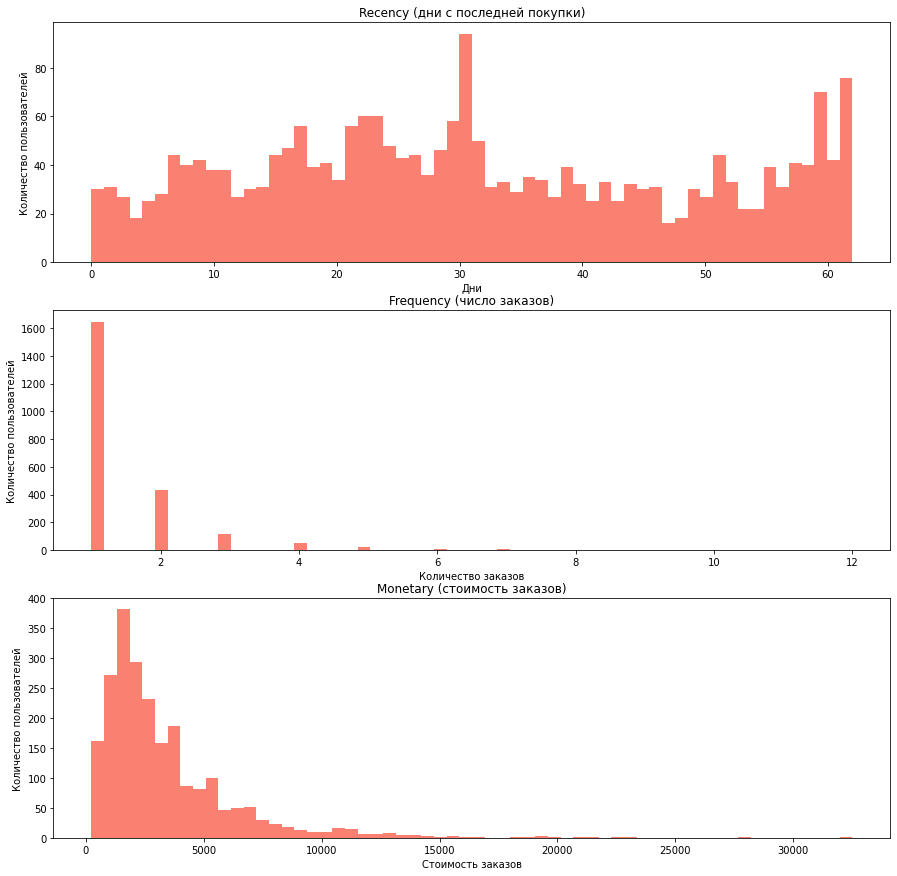

In [62]:
fig, axes = plt.subplots(3, 1, figsize = (15, 15))

axes[0].hist(rfm_orders_df['recency'], bins = 60, color = 'salmon')
axes[0].set_title('Recency (дни с последней покупки)')
axes[0].set_xlabel('Дни')
axes[0].set_ylabel('Количество пользователей')

axes[1].hist(rfm_orders_df['frequency'], bins = 60, color = 'salmon')
axes[1].set_title('Frequency (число заказов)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество пользователей')

axes[2].hist(rfm_orders_df['monetary_value'], bins = 60, color = 'salmon')
axes[2].set_title('Monetary (стоимость заказов)')
axes[2].set_xlabel('Стоимость заказов')
axes[2].set_ylabel('Количество пользователей')

plt.show()

Большинство пользователей сделали один заказ. Четверть из них сделали заказ повторно, дальше идёт резкое снижение. Пик заказов приходится на отметке до ~2500, цены ближе к лефой границе графика. На графике дней с последней покупки видна волна, возможно сезонность, есть пик на 30 день.

**Задача 3.2.** Выделим RFM-сегменты и изучим распределение пользователей по ним.
    
Применим следующие подходы к выделению RFM сегментов:
- Recency — разделите на три равные группы.
- Frequency —  разделите на три группы: 
    - пользователи с 1 заказом (F-сегмент с небольшим количеством заказов);
    - пользователи с 2 заказами (F-сегмент со средним количеством заказов);
    - пользователи с 3 и более заказами (F-сегмент с большим количеством заказов).
- Monetary — разделите на три группы по 33-му и 66-му перцентилям.
    
После этого посчитаем количество покупателей в каждом сегменте.

In [63]:
rfm_orders_df = rfm_orders_df.sort_values('recency', ascending = True).reset_index(drop = True)
n_users = len(rfm_orders_df)
recency_size = n_users // 3
labels = np.repeat(['1', '2', '3'], [recency_size, recency_size, n_users - 2 * recency_size])
rfm_orders_df['r'] = labels

conditions = [
    rfm_orders_df['frequency'] == 1,
    rfm_orders_df['frequency'] == 2,
    rfm_orders_df['frequency'] >= 3
]
rfm_orders_df['f'] = np.select(conditions, ['1', '2', '3'])

rfm_orders_df['m'] = pd.qcut(
    rfm_orders_df['monetary_value'], 
    q = [0, 0.33, 0.66, 1], 
    labels = ['1', '2', '3']
).astype(str)

rfm_orders_df['rfm_group'] = rfm_orders_df['r'] + rfm_orders_df['f'] + rfm_orders_df['m']

rfm_orders_df

,user_id,recency,frequency,monetary_value,r,f,m,rfm_group
0,616472,0,1,1400.000,1,1,1,111
1,644868,1,1,3889.200,1,1,3,113
2,562688,1,1,2968.000,1,1,2,112
3,645177,1,1,2450.000,1,1,2,112
4,642610,1,1,1400.000,1,1,1,111
...,...,...,...,...,...,...,...,...
2287,567627,62,2,6483.876,3,2,3,323
2288,566563,62,1,3024.000,3,1,2,312
2289,566584,62,3,6160.000,3,3,3,333
2290,566800,62,1,4984.000,3,1,3,313


In [64]:
rfm_group = rfm_orders_df.groupby('rfm_group').agg({'user_id':'nunique'}).reset_index()
rfm_group['user_share'] = rfm_group['user_id'] / rfm_group['user_id'].sum()
rfm_group = rfm_group.sort_values('user_share', ascending = False).reset_index(drop = True)

rfm_group

,rfm_group,user_id,user_share
0,311,251,0.109511
1,111,245,0.106894
2,211,238,0.103839
3,312,232,0.101222
4,112,197,0.085951
5,212,192,0.083770
6,113,107,0.046684
7,213,101,0.044066
8,223,96,0.041885
9,123,91,0.039703


Лидирующие позицие занимают клиенты, совершившие всего одну покупку с низкими тратами. Это больше 30% пользователей, стоит проверить источник их привлечения, если он платный - пересмотреть траты. Лояльными эти группы не становятся и выручку  приносят минимальную. По группам видно, что люди всё же возвращаются в приложение и готовы платить больше. Группы с высокими тратами высоко в рейтинге, среди них много давних. Возможно более ранние акции привлечения лучше работали. Важно удержать людей на ранних этапах, мотивировать сделать больше двух заказов.

---

## K-Means кластеризация

Чтобы лучше понимать поведение ресторанов и предлагать им персонализированные условия сотрудничества, а также создавать персонализированные предложения для пользователей, маркетологи запросили кластеризацию ресторанов по следующим параметрам:
- Общее количество заказов;
- Средняя стоимость заказа;
- Общее число заказанных уникальных блюд (ассортимент ресторана).

С помощью метода K-Means разделим рестораны на кластеры, отражающие различные модели работы и целевые сегменты. Это позволит выделить группы ресторанов с похожими характеристиками и разрабатывать для них эффективные маркетинговые стратегии.

**Задача 4.1.** Подготовим данные для кластеризации и для каждого ресторана подсчитаем:
- Общее количество заказов;
- Средняя стоимость заказа;
- Общее число заказанных уникальных блюд (ассортимент ресторана).

In [65]:
orders_df.head()

,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission,order_recency
0,0917eb10-d393-4d7e-a911-8721571cb499,567210,mobile,6,organic,2021-05-01,171460594,order,2021-05-01 14:52:17,56edd124dfa44656afe0c0d041eba562,25349.0,590313.0,1143.156,28.1,0.04,62 days 09:07:43
1,0c858e35-00cb-4d8b-ad9f-d19b3b627c2f,210853,desktop,6,organic,2021-05-01,171515445,order,2021-05-01 18:45:48,39b7eab4f4704ed2886fafe171489960,35102.0,590707.0,1663.200,18.2,0.11,62 days 05:14:12
2,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:34:35,55d4027ac83e438f9f893892f6903409,25069.0,591008.0,3500.000,10.8,0.05,62 days 02:25:25
3,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:43:34,1d6bb74687104fa1953924c9684fe624,31738.0,591028.0,610.400,38.7,0.08,62 days 02:16:26
4,0eb15742-903e-450c-9252-063cff29a094,567631,desktop,6,organic,2021-05-01,171529844,order,2021-05-01 21:44:52,1d6bb74687104fa1953924c9684fe624,31738.0,591034.0,1220.800,15.6,0.08,62 days 02:15:08


In [66]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3319 entries, 0 to 3318
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype          
---  ------         --------------  -----          
 0   visitor_uuid   3319 non-null   object         
 1   user_id        3319 non-null   Int64          
 2   device_type    3319 non-null   object         
 3   city_id        3319 non-null   int64          
 4   source         3319 non-null   object         
 5   first_date     3319 non-null   datetime64[ns] 
 6   visit_id       3319 non-null   int64          
 7   event          3319 non-null   object         
 8   datetime       3319 non-null   datetime64[ns] 
 9   rest_id        3319 non-null   object         
 10  object_id      3319 non-null   float64        
 11  order_id       3319 non-null   float64        
 12  revenue        3319 non-null   float64        
 13  delivery       3319 non-null   float64        
 14  commission     3319 non-null   float64        
 15  orde

In [67]:
km_rest = orders_df.groupby('rest_id').agg(
    orders = ('order_id', 'count'),
    avg_order = ('revenue', 'mean'),
    dishes = ('object_id', 'nunique')
).reset_index()

km_rest

,rest_id,orders,avg_order,dishes
0,1be5a933aab34fbab594bebba48e976e,138,2127.893681,26
1,1d6bb74687104fa1953924c9684fe624,100,2423.057000,18
2,2c6095730b514c189ee41c65f03febc3,7,1768.000000,4
3,3247a3b5f9494812a3c1a73c5b61f004,30,2741.330667,4
4,39b7eab4f4704ed2886fafe171489960,31,2008.980129,5
5,43e40bacafe8409bb5592877a42d737e,39,3233.673333,6
6,4a693ca500b44ba499f92a724aec5f17,100,2713.900000,12
7,4b9cde3378c447ed81c2c6d4854d4f7e,7,2544.000000,5
8,55d4027ac83e438f9f893892f6903409,920,2501.659635,72
9,55d6470712ee48e98509478ad6aa18ee,5,4754.400000,2


У данных будет 3 признака, посмотрим на график.

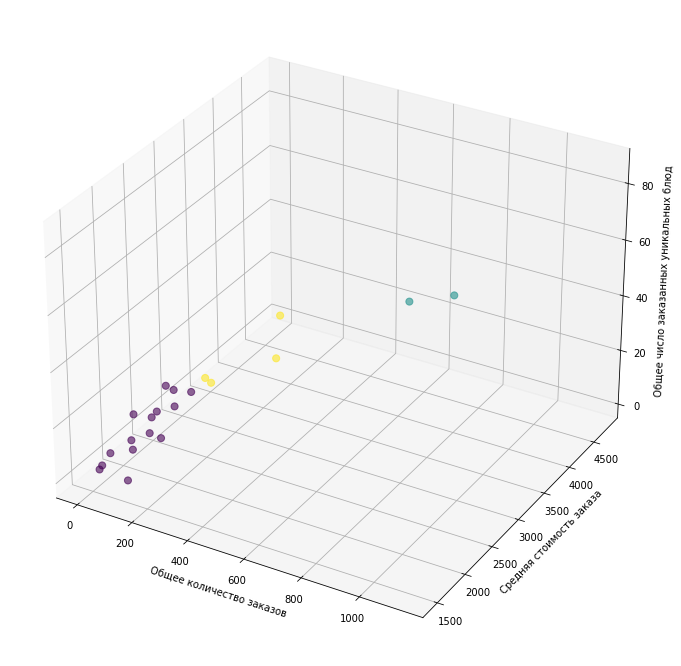

In [68]:
feat = ['orders', 'avg_order', 'dishes']
x = km_rest[feat].values

scal = StandardScaler()
x_scal = scal.fit_transform(x)

kmeans = KMeans(n_clusters = 3)
labels = kmeans.fit_predict(x_scal)

fig = plt.figure(figsize = (12, 12))
ax = fig.add_subplot(111, projection = '3d')

ax.scatter(
   km_rest['orders'], km_rest['avg_order'], km_rest['dishes'],
   c = labels, cmap = 'viridis', s = 50, alpha = 0.6
)

ax.set_xlabel('Общее количество заказов')
ax.set_ylabel('Средняя стоимость заказа')
ax.set_zlabel('Общее число заказанных уникальных блюд')

plt.show()

Плотность у точек разная, на глаз 3 кластера.

**Задача 4.2.** Нормализуем данные и найдём оптимальное количество кластеров, используя метод `.inertia_`. Построим график зависимости инерции от числа кластеров (метод «локтя») и предположим оптимальное количество кластеров.

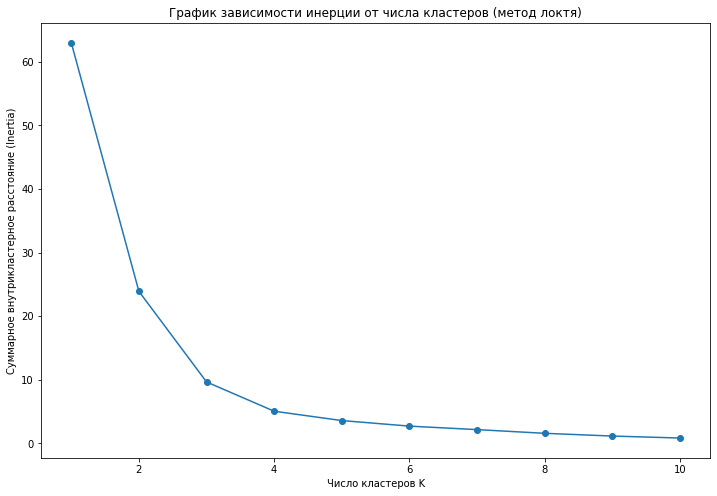

In [69]:
i = []

min_k = 1
max_k = 10

plt.figure(figsize = (12, 8))

for k in range(min_k, max_k + 1):
   km = KMeans(n_clusters = k)
   km.fit_transform(x_scal)
   i.append(km.inertia_)

plt.plot(range(min_k, max_k + 1), i, marker = 'o')
plt.xlabel('Число кластеров K')
plt.ylabel('Суммарное внутрикластерное расстояние (Inertia)')
plt.title('График зависимости инерции от числа кластеров (метод локтя)')
plt.show()

Выделить 3 кластера будет оптимально.

**Задача 4.3.** Проведём кластеризацию, проанализируем полученные результаты и рассчитаем средние значения по каждому кластеру.
    
После этого визуализируйем результаты, чтобы проследить зависимость признаков друг от друга. Построим две визуализации, на которые нанесём все кластеры:
- Средний чек в зависимости от количества заказов;
- Количество блюд в зависимости от количества заказов.

In [70]:
sorted_indices = np.argsort(kmeans.cluster_centers_[:, 1])
sorted_centroids = kmeans.cluster_centers_[sorted_indices]

centroids_df = pd.DataFrame(
   sorted_centroids,
   columns = ['orders', 'avg_order', 'dishes'],
   index = [f'Кластер {i + 1}' for i in range(kmeans.n_clusters)]
)

pd.options.display.float_format = '{:.3f}'.format

In [71]:
real_centroids = scal.inverse_transform(kmeans.cluster_centers_)

centroids_real = pd.DataFrame(
    real_centroids,
    columns = ['orders', 'avg_order', 'dishes'],
    index = [f'Кластер {i+1}' for i in range(kmeans.n_clusters)]
)

centroids_real = centroids_real.round(1)

centroids_real

,orders,avg_order,dishes
Кластер 1,65.900,2073.100,8.800
Кластер 2,1026.000,2329.800,79.000
Кластер 3,69.800,3772.900,4.800


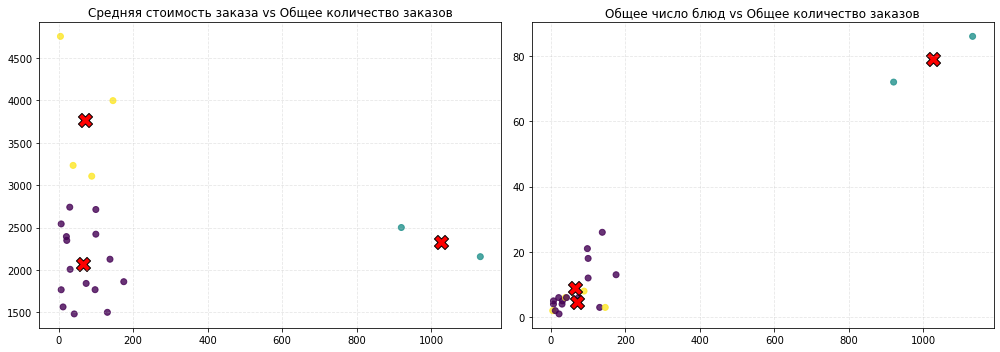

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

km_rest['cluster'] = kmeans.labels_

ax1.scatter(km_rest['orders'], km_rest['avg_order'], c = km_rest['cluster'], cmap = 'viridis', alpha = 0.8)
ax1.scatter(centroids_real['orders'], centroids_real['avg_order'], s = 200, c = 'red', marker = 'X', edgecolors = 'black')
ax1.set_title('Средняя стоимость заказа vs Общее количество заказов')
ax1.grid(True, linestyle = '--', alpha = 0.3)

ax2.scatter(km_rest['orders'], km_rest['dishes'], c = km_rest['cluster'], cmap = 'viridis', alpha = 0.8)
ax2.scatter(centroids_real['orders'], centroids_real['dishes'], s = 200, c = 'red', marker = 'X', edgecolors = 'black')
ax2.set_title('Общее число блюд vs Общее количество заказов')
ax2.grid(True, linestyle = '--', alpha = 0.3)

plt.tight_layout()
plt.show()

Первый кластер (фиолетовый): Самый объёмный, заказы в этих точках сделали до 200 раз, средний чек низкий (до 2500 рублей), разнообрази меню среднее (до 30 позиций). Скорее всего это небольшие заведения. Стоит продумать мотивацию пользователей к более частым заказам, найти новые, более эффективные источники привлечеия, поощрять акциями и привилегиями.

Второй кластер (бирюзовый): есть два явно выделяющихся ресторана, они самые популярные (около 900 - 1100 заказов), у них хороший средний чек (2200–2500 рублей) и разнообразное меню, из которого заказывают множество блюд (70+). Широкий ассортимент явно привлекает пользователей,  возможно у них есть комбо, завтраки/обеды/ужины, представлены различные кухни. Стоит изучить эти рестораны, может добавить похожие заведения в сервис доставки, или побудить другие точки следовать удачному примеру.

Третий кластер (желтый): Схожая по количеству заказов с первым кластегом группа. Выделяется более дорогими чеками (выше 3000 рублей), в меню заведений представлено очень мало позиций (до 10). Стоит узнать, как они  делают такую высокую среднюю стоимость заказов с такими блюдами, изучить концепции заведений, откуда приходит трафик.

---

## Итоговый вывод и рекомендации

Анализ воронки показал проблемы на этапе подтверждения телефона у мобильной версии сервиса доставки, разработчики указывали на изменения в системе. Просадка воронки есть и у десктопной версии на этапе регистрации. После этих шагов большинство клиентов остаются для заказа, значит из-за этого узкого места воронки сильно теряется доход. Проблема скорее  всего техническая (судя по графику времени между шагами) или в интерфейсе приложения.

RFM сегментация определила, что людей, совершивших 1 заказ, подавляющее количество. Они готовы тратить деньги, но  возвращается за вторым заказом только четверть, за  3+ еденицы. Стоит проверить источники привлечения, их эффективность и окупаемость. Те, кто сделал единичный заказ и забросил сервис могли быть не целевой аудиторией. Провести маркетинговые акции для тех, кто совершил 2+ заказа, для создания платящего ядра лояльных пользователей.

Кластеризация ресторанов показала, что есть 2 основных заведения. Они составляют основной объём по заказам, предлагают обширное меню по умеренным ценам. Остальные 19 заведений отработали меньше 200 заказов, ценны в них сильно варьируются при более скромном меню. Если добавить больше крупных заведений в сервис, можно увеличить постоянную базу клиентов и частоту заказов, нужно больше ресторанов, как во стором кластере. Остальным двум надо обновить систему привлечения и стимуляции повторных заказов.